In [1]:
!pip install --upgrade ultralytics 
!pip install --upgrade -U ray[tune]

**Important!** The full training takes several hours: run this notebook on Kaggle ("Save Version" → "Save & Run All").
1. Select the accelerator "GPU T4 x2". GPU P100 is not supported by the current PyTorch build (CUDA 13 requires compute capability 7.5+).
2. Leave "Internet on": the dataset and the model weights are downloaded by the code.

[![Open In Kaggle](https://kaggle.com/static/images/open-in-kaggle.svg)](https://kaggle.com/kernels/welcome?src=https://github.com/BetterED-Neoversity/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/blob/main/notebooks/Module_4_Lecture_7_Class_kaggle.ipynb) [![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/BetterED-Neoversity/DEEP-LEARNING-FOR-COMPUTER-VISION-AND-NLP/blob/main/notebooks/Module_4_Lecture_7_Class_kaggle.ipynb)



[CSS (Construction Site Safety) Dataset](https://www.kaggle.com/datasets/snehilsanyal/construction-site-safety-image-dataset-roboflow):

- Labels in this dataset:
    - 0: Hardhat
    - 1: Mask
    - 2: NO-Hardhat
    - 3: NO-Mask
    - 4: NO-Safety Vest
    - 5: Person
    - 6: Safety Cone
    - 7: Safety Vest
    - 8: Machinery
    - 9: Vehicle


- Label Annotation: YOLO format (.txt)
     - `[class_id, center_x, center_y, width, height]`
      
___      

In [2]:
import warnings
warnings.filterwarnings("ignore")

import os
import re
import glob
import random
import yaml

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
import seaborn as sns

# import IPython.display as display
from PIL import Image
import cv2

from ultralytics import YOLO

%matplotlib inline

!wandb disabled # use if you have Weights and Biases installed

wandb: Updated settings file /content/wandb/settings
W&B disabled.


In [3]:
# Download the dataset from Kaggle (a Kaggle account is not required for public datasets)
# and copy it to the folder used in this notebook
import kagglehub
import shutil

DATASET_DIR = './data/Module_4_Lecture_1_Construction_Site_Safety'

if not os.path.isdir(DATASET_DIR):
    path = kagglehub.dataset_download('snehilsanyal/construction-site-safety-image-dataset-roboflow')
    shutil.copytree(os.path.join(path, 'css-data'), DATASET_DIR)

In [4]:
# Folder structure: train / valid / test, each with images and labels
for split in ['train', 'valid', 'test']:
    print(split, sorted(os.listdir(os.path.join(DATASET_DIR, split))))

train ['images', 'labels']
valid ['images', 'labels']
test ['images', 'labels']


In [5]:
class CFG:
    DEBUG = False # Set to True to make quick experiments
    FRACTION = 0.05 if DEBUG else 1.0 # Specifies the fraction of the dataset to use for training. Allows for training on a subset of the full dataset, useful for experiments or when resources are limited.
    SEED = 42

    # classes
    CLASSES = ['Hardhat', 'Mask', 'NO-Hardhat', 'NO-Mask',
               'NO-Safety Vest', 'Person', 'Safety Cone',
               'Safety Vest', 'machinery', 'vehicle']
    NUM_CLASSES_TO_TRAIN = len(CLASSES)

    # training
    EPOCHS = 3 if DEBUG else 70 # 100
    BATCH_SIZE = 8 # 16

    BASE_MODEL = 'yolov9e' # yolov8n, yolov8s, yolov8m, yolov8l, yolov8x, yolov9c, yolov9e
    BASE_MODEL_WEIGHTS = f'{BASE_MODEL}.pt'
    EXP_NAME = f'ppe_css_{EPOCHS}_epochs'

    OPTIMIZER = 'auto' # SGD, Adam, Adamax, AdamW, NAdam, RAdam, RMSProp, auto
    LR = 1e-3
    LR_FACTOR = 0.01 # Final learning rate as a fraction of the initial rate = (lr0 * lrf), used in conjunction with schedulers to adjust the learning rate over time.
    WEIGHT_DECAY = 5e-4 # L2 regularization term, penalizing large weights to prevent overfitting.
    DROPOUT = 0.0
    PATIENCE = 20
    PROFILE = False
    LABEL_SMOOTHING = 0.0

    # paths
    CUSTOM_DATASET_DIR = './data/Module_4_Lecture_1_Construction_Site_Safety/'
    OUTPUT_DIR = './'

Create ```data.yaml``` file properly formatted to be used by Yolo

In [6]:
dict_file = {
    'train': os.path.join(CFG.CUSTOM_DATASET_DIR, 'train'),
    'val': os.path.join(CFG.CUSTOM_DATASET_DIR, 'valid'),
    'test': os.path.join(CFG.CUSTOM_DATASET_DIR, 'test'),
    'nc': CFG.NUM_CLASSES_TO_TRAIN,
    'names': CFG.CLASSES
    }

with open(os.path.join(CFG.OUTPUT_DIR, 'data.yaml'), 'w+') as file:
    yaml.dump(dict_file, file)

In [7]:
# read yaml file created
def read_yaml_file(file_path = CFG.CUSTOM_DATASET_DIR):
    with open(file_path, 'r') as file:
        try:
            data = yaml.safe_load(file)
            return data
        except yaml.YAMLError as e:
            print("Error reading YAML:", e)
            return None

# print it with newlines
def print_yaml_data(data):
    formatted_yaml = yaml.dump(data, default_style=False)
    print(formatted_yaml)

file_path = os.path.join(CFG.OUTPUT_DIR, 'data.yaml')
yaml_data = read_yaml_file(file_path)

if yaml_data:
    print_yaml_data(yaml_data)

names:
- Hardhat
- Mask
- NO-Hardhat
- NO-Mask
- NO-Safety Vest
- Person
- Safety Cone
- Safety Vest
- machinery
- vehicle
nc: 10
test: ./data/Module_4_Lecture_1_Construction_Site_Safety/test
train: ./data/Module_4_Lecture_1_Construction_Site_Safety/train
val: ./data/Module_4_Lecture_1_Construction_Site_Safety/valid



Visualize one image

In [8]:
def display_image(image, print_info = True, hide_axis = False):
    if isinstance(image, str):  # Check if it's a file path
        img = Image.open(image)
        plt.imshow(img)
    elif isinstance(image, np.ndarray):  # Check if it's a NumPy array
        image = image[..., ::-1]  # BGR to RGB
        img = Image.fromarray(image)
        plt.imshow(img)
    else:
        raise ValueError("Unsupported image format")

    if print_info:
        print('Type: ', type(img), '\n')
        print('Shape: ', np.array(img).shape, '\n')

    if hide_axis:
        plt.axis('off')

    plt.show()

Type:  <class 'PIL.JpegImagePlugin.JpegImageFile'> 

Shape:  (640, 640, 3) 



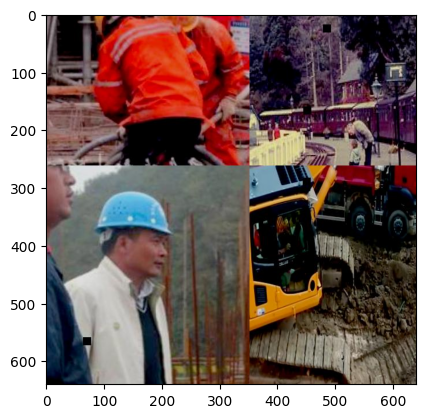

In [9]:
example_image_path = CFG.CUSTOM_DATASET_DIR + 'train/images/-2297-_png_jpg.rf.9fff3740d864fbec9cda50d783ad805e.jpg'
display_image(example_image_path, print_info = True, hide_axis = False)

Visualize many images

In [10]:
def plot_random_images_from_folder(folder_path, num_images=20, seed=CFG.SEED):
    
    random.seed(seed)

    # Get a list of image files in the folder
    image_files = [f for f in os.listdir(folder_path) if f.endswith(('.jpg', '.png', '.jpeg', '.gif'))]

    # Ensure that we have at least num_images files to choose from
    if len(image_files) < num_images:
        raise ValueError("Not enough images in the folder")

    # Randomly select num_images image files
    selected_files = random.sample(image_files, num_images)

    # Create a subplot grid
    num_cols = 5
    num_rows = (num_images + num_cols - 1) // num_cols
    fig, axes = plt.subplots(num_rows, num_cols, figsize=(12, 8))

    for i, file_name in enumerate(selected_files):
        # Open and display the image using PIL
        img = Image.open(os.path.join(folder_path, file_name))
        
        if num_rows == 1:
            ax = axes[i % num_cols]
        else:
            ax = axes[i // num_cols, i % num_cols]
        
        ax.imshow(img)
        ax.axis('off')
        # ax.set_title(file_name)

    # Remove empty subplots
    for i in range(num_images, num_rows * num_cols):
        if num_rows == 1:
            fig.delaxes(axes[i % num_cols])
        else:
            fig.delaxes(axes[i // num_cols, i % num_cols])

    plt.tight_layout()
    plt.show()

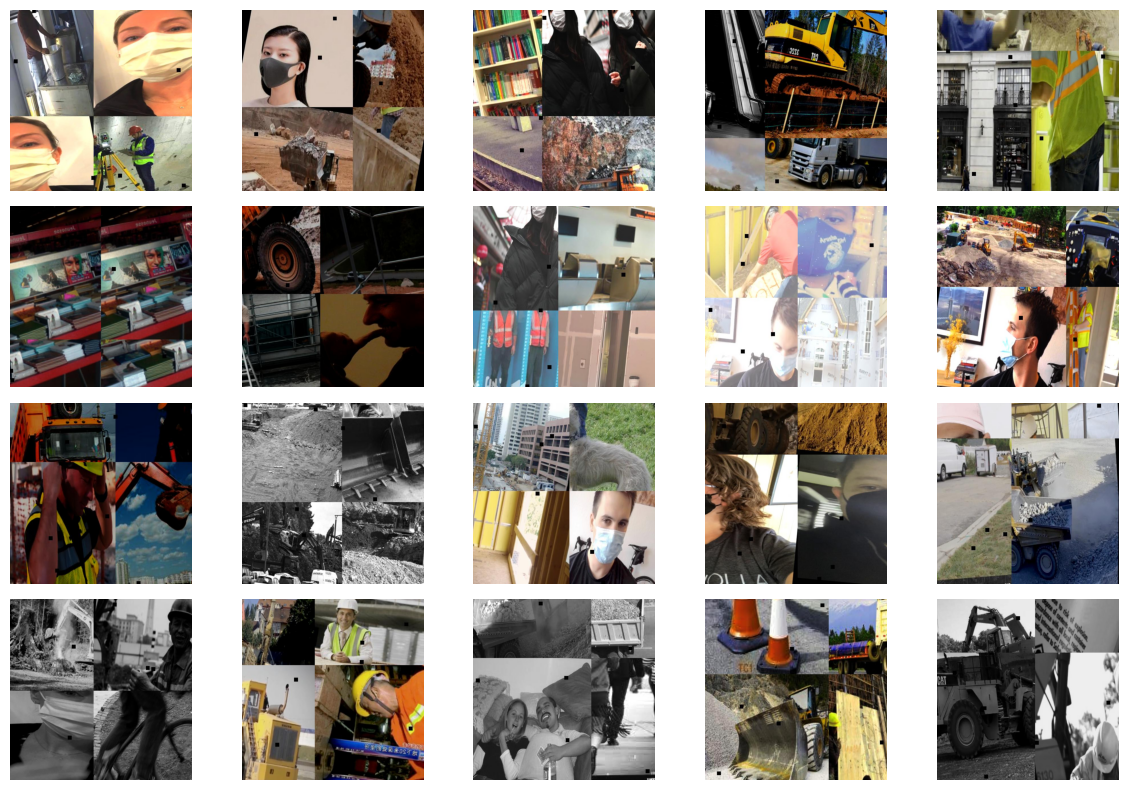

In [11]:
folder_path = CFG.CUSTOM_DATASET_DIR + 'train/images/'
plot_random_images_from_folder(folder_path, num_images=20, seed=CFG.SEED)

Image properties

In [12]:
def get_image_properties(image_path):
    # Read the image file
    img = cv2.imread(image_path)

    # Check if the image file is read successfully
    if img is None:
        raise ValueError("Could not read image file")

    # Get image properties
    properties = {
        "width": img.shape[1],
        "height": img.shape[0],
        "channels": img.shape[2] if len(img.shape) == 3 else 1,
        "dtype": img.dtype,
    }

    return properties

In [13]:
img_properties = get_image_properties(example_image_path)
img_properties

{'width': 640, 'height': 640, 'channels': 3, 'dtype': dtype('uint8')}

Dataset statistics

In [14]:
class_idx = {str(i): CFG.CLASSES[i] for i in range(CFG.NUM_CLASSES_TO_TRAIN)}

class_stat = {}
data_len = {}
class_info = []

for mode in ['train', 'valid', 'test']:
    class_count = {CFG.CLASSES[i]: 0 for i in range(CFG.NUM_CLASSES_TO_TRAIN)}

    path = os.path.join(CFG.CUSTOM_DATASET_DIR, mode, 'labels')

    for file in os.listdir(path):
        with open(os.path.join(path, file)) as f:
            lines = f.readlines()

            for cls in set([line[0] for line in lines]):
                class_count[class_idx[cls]] += 1

    data_len[mode] = len(os.listdir(path))
    class_stat[mode] = class_count

    class_info.append({'Mode': mode, **class_count, 'Data_Volume': data_len[mode]})

dataset_stats_df = pd.DataFrame(class_info)
with pd.option_context('display.max_columns', None): 
    display(dataset_stats_df)


,Mode,Hardhat,Mask,NO-Hardhat,NO-Mask,NO-Safety Vest,Person,Safety Cone,Safety Vest,machinery,vehicle,Data_Volume
0,train,1314,1096,1380,1531,1864,2526,631,1319,2101,744,2605
1,valid,42,19,37,44,56,84,13,28,26,16,114
2,test,30,16,25,30,36,59,8,22,22,15,82


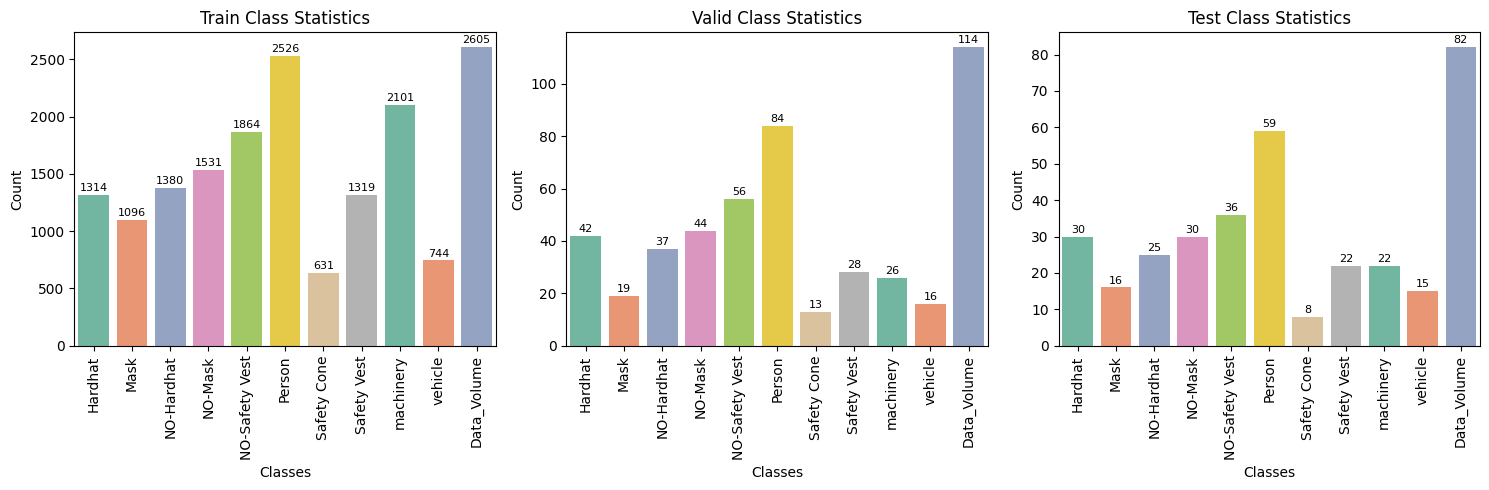

In [15]:
# Create subplots with 1 row and 3 columns
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# Plot vertical bar plots for each mode in subplots
for i, mode in enumerate(['train', 'valid', 'test']):
    sns.barplot(
        data=dataset_stats_df[dataset_stats_df['Mode'] == mode].drop(columns='Mode'),
        orient='v',
        ax=axes[i],
        palette='Set2'
    )
    
    axes[i].set_title(f'{mode.capitalize()} Class Statistics')
    axes[i].set_xlabel('Classes')
    axes[i].set_ylabel('Count')
    axes[i].tick_params(axis='x', rotation=90) 

    # Add annotations on top of each bar
    for p in axes[i].patches:
        axes[i].annotate(f"{int(p.get_height())}", (p.get_x() + p.get_width() / 2., p.get_height()),
                         ha='center', va='center', fontsize=8, color='black', xytext=(0, 5),
                         textcoords='offset points')

plt.tight_layout()
plt.show()

Base Model Inference

Checking the power of the pretrained model inference on the CSS dataset

In [16]:
model = YOLO(CFG.BASE_MODEL_WEIGHTS)

results = model.predict(
    source = example_image_path,

    classes = [0],
    conf = 0.30,
#     device = [0,1], # inference with dual GPU
    device = None, # None = auto: GPU if available, otherwise CPU
    imgsz = (img_properties['height'], img_properties['width']),

    save = True,
    save_txt = True,
    save_conf = True,
    exist_ok = True,
)


image 1/1 /content/data/Module_4_Lecture_1_Construction_Site_Safety/train/images/-2297-_png_jpg.rf.9fff3740d864fbec9cda50d783ad805e.jpg: 640x640 7 persons, 29.7ms
Speed: 25.2ms preprocess, 29.7ms inference, 49.0ms postprocess per image at shape (1, 3, 640, 640)
Results saved to /content/runs/detect/predict
1 label saved to /content/runs/detect/predict/labels


Type:  <class 'PIL.JpegImagePlugin.JpegImageFile'> 

Shape:  (640, 640, 3) 



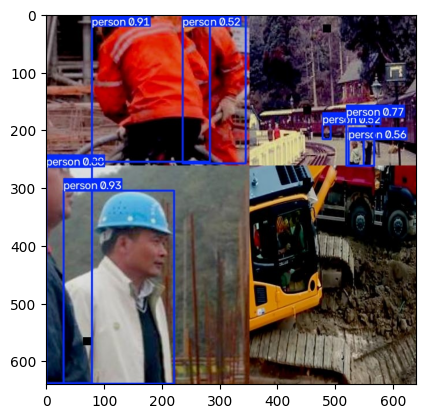

In [17]:
### check predictions with base model
example_image_inference_output = example_image_path.split('/')[-1]
display_image(f'runs/detect/predict/{example_image_inference_output}')

Train

[Arguments for training](https://docs.ultralytics.com/modes/train/#arguments)

In [18]:
print('Model: ', CFG.BASE_MODEL_WEIGHTS)
print('Epochs: ', CFG.EPOCHS)
print('Batch: ', CFG.BATCH_SIZE)

Model:  yolov9e.pt
Epochs:  70
Batch:  8


In [19]:
### Load pre-trained YOLO model
model = YOLO(CFG.BASE_MODEL_WEIGHTS)

In [20]:
%%time

### train
model.train(
    data = os.path.join(CFG.OUTPUT_DIR, 'data.yaml'),

    task = 'detect',

    imgsz = (img_properties['height'], img_properties['width']),

    epochs = CFG.EPOCHS,
    batch = CFG.BATCH_SIZE,
    optimizer = CFG.OPTIMIZER,
    lr0 = CFG.LR,
    lrf = CFG.LR_FACTOR,
    weight_decay = CFG.WEIGHT_DECAY,
    dropout = CFG.DROPOUT,
    fraction = CFG.FRACTION,
    patience = CFG.PATIENCE,
    profile = CFG.PROFILE,
    label_smoothing = CFG.LABEL_SMOOTHING,

    name = f'{CFG.BASE_MODEL}_{CFG.EXP_NAME}',
    seed = CFG.SEED,
    
    val = True,
    amp = True,    
    exist_ok = True,
    resume = False,
    device = [0], #  [0,1] 
#     device = None, # CPU run
    verbose = False,
)

WARNING ⚠️ 'label_smoothing' is deprecated and will be removed in the future.
Ultralytics 8.4.215 🚀 Python-3.13.12 torch-2.14.1+cu130 CUDA:0 (NVIDIA GeForce RTX 3090, 24124MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=8, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=./data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=70, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=(640, 640), iou=None, kobj=1.0, line_width=None, lr0=0.001, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov9e.pt, momentum=0.937, mosaic=1.0,

ultralytics.utils.metrics.DetMetrics object with attributes:

ap_class_index: array([0, 1, 2, 3, 4, 5, 6, 7, 8, 9])
box: ultralytics.utils.metrics.Metric object
confusion_matrix: <ultralytics.utils.metrics.ConfusionMatrix object at 0x72864c5c52b0>
curves: ['Precision-Recall(B)', 'F1-Confidence(B)', 'Precision-Confidence(B)', 'Recall-Confidence(B)']
curves_results: [[array([          0,    0.001001,    0.002002,    0.003003,    0.004004,    0.005005,    0.006006,    0.007007,    0.008008,    0.009009,     0.01001,    0.011011,    0.012012,    0.013013,    0.014014,    0.015015,    0.016016,    0.017017,    0.018018,    0.019019,     0.02002,    0.021021,    0.022022,    0.023023,
          0.024024,    0.025025,    0.026026,    0.027027,    0.028028,    0.029029,     0.03003,    0.031031,    0.032032,    0.033033,    0.034034,    0.035035,    0.036036,    0.037037,    0.038038,    0.039039,     0.04004,    0.041041,    0.042042,    0.043043,    0.044044,    0.045045,    0.046046,    0.0

[Export mode](https://docs.ultralytics.com/modes/export/) is used for exporting a YOLOv9 model to a format that can be used for deployment. In this mode, the model is converted to a format that can be used by other software applications or hardware devices. This mode is useful when deploying the model to production environments.

In [21]:
# Export the model
model.export(
    format = 'onnx', # openvino, onnx, engine, tflite
    imgsz = (img_properties['height'], img_properties['width']),
    half = False,
    int8 = False,
    simplify = False,
    nms = False,
)

WARNING ⚠️ 'int8' is deprecated and will be removed in the future. Use 'quantize' instead.
Ultralytics 8.4.215 🚀 Python-3.13.12 torch-2.14.1+cu130 CPU (AMD Ryzen 9 5900X 12-Core Processor)
WARNING ⚠️ This model has no one-to-one head; using one-to-many outputs.
YOLOv9e summary (fused): 279 layers, 57,384,110 parameters, 0 gradients, 189.2 GFLOPs

PyTorch: starting from '/content/runs/detect/yolov9e_ppe_css_70_epochs/weights/best.pt' with input shape (1, 3, 640, 640) BCHW and output shape(s) (1, 14, 8400) (111.8 MB)

ONNX: starting export with onnx 1.23.2 opset 18...
ONNX: export success ✅ 2.6s, saved as '/content/runs/detect/yolov9e_ppe_css_70_epochs/weights/best.onnx' (219.3 MB)

Export complete (3.3s)
Results saved to /content/runs/detect/yolov9e_ppe_css_70_epochs/weights/best.onnx
Predict:         yolo predict task=detect model=/content/runs/detect/yolov9e_ppe_css_70_epochs/weights/best.onnx imgsz=640 
Validate:        yolo val task=detect model=/content/runs/detect/yolov9e_ppe_css_

'/content/runs/detect/yolov9e_ppe_css_70_epochs/weights/best.onnx'

Train results

In [22]:
results_paths = [
    i for i in
    glob.glob(f'{CFG.OUTPUT_DIR}runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/*.png') +
    glob.glob(f'{CFG.OUTPUT_DIR}runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/*.jpg')
    if 'batch' not in i
]

results_paths

['./runs/detect/yolov9e_ppe_css_70_epochs/BoxR_curve.png',
 './runs/detect/yolov9e_ppe_css_70_epochs/BoxP_curve.png',
 './runs/detect/yolov9e_ppe_css_70_epochs/confusion_matrix_normalized.png',
 './runs/detect/yolov9e_ppe_css_70_epochs/confusion_matrix.png',
 './runs/detect/yolov9e_ppe_css_70_epochs/BoxF1_curve.png',
 './runs/detect/yolov9e_ppe_css_70_epochs/results.png',
 './runs/detect/yolov9e_ppe_css_70_epochs/BoxPR_curve.png',
 './runs/detect/yolov9e_ppe_css_70_epochs/labels.jpg']

./runs/detect/yolov9e_ppe_css_70_epochs/BoxF1_curve.png


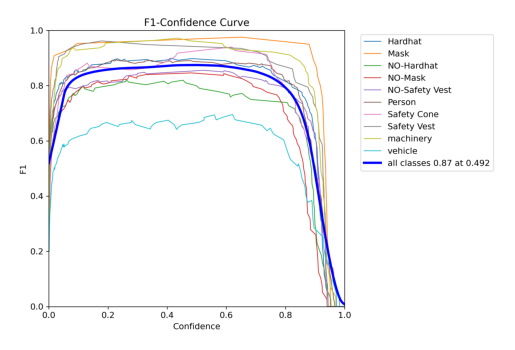



./runs/detect/yolov9e_ppe_css_70_epochs/BoxPR_curve.png


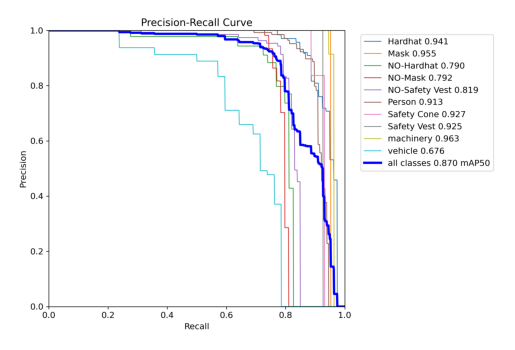



./runs/detect/yolov9e_ppe_css_70_epochs/BoxP_curve.png


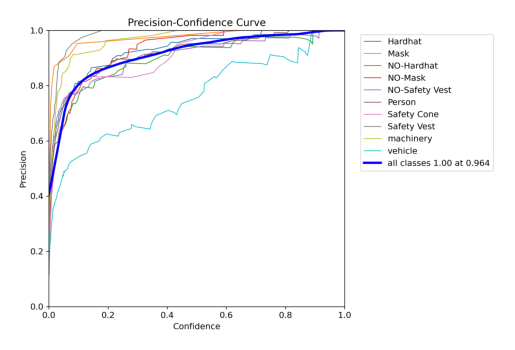



./runs/detect/yolov9e_ppe_css_70_epochs/BoxR_curve.png


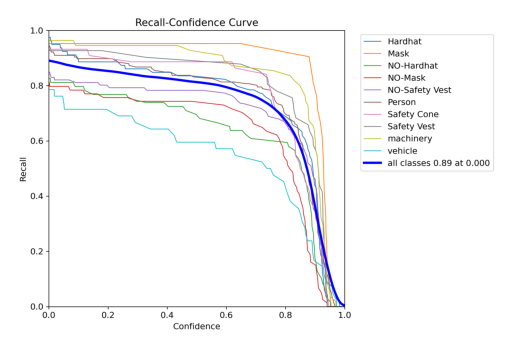



./runs/detect/yolov9e_ppe_css_70_epochs/confusion_matrix.png


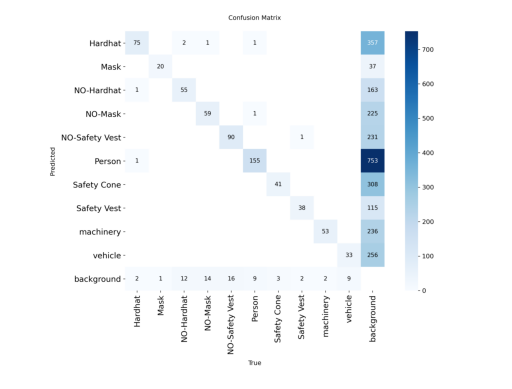



./runs/detect/yolov9e_ppe_css_70_epochs/confusion_matrix_normalized.png


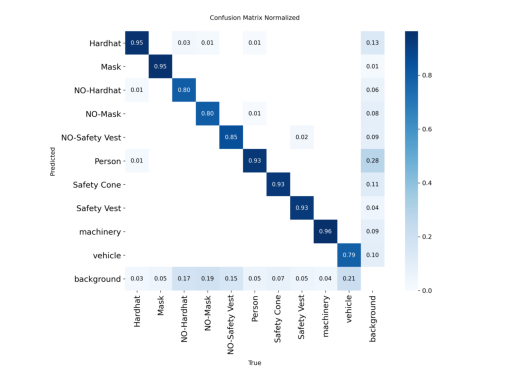



./runs/detect/yolov9e_ppe_css_70_epochs/labels.jpg


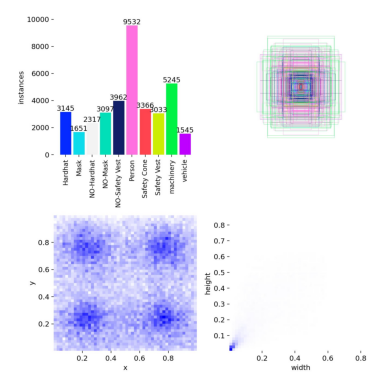



./runs/detect/yolov9e_ppe_css_70_epochs/results.png


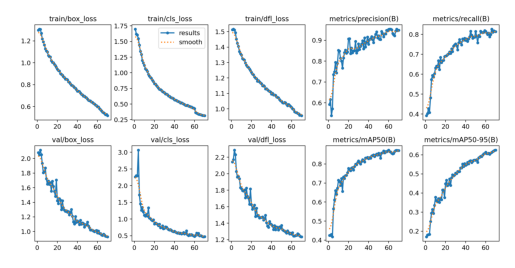

In [23]:
for file in sorted(results_paths):
    print(file)
    display_image(file, print_info = False, hide_axis = True)
    print('\n')

Loss

- For Ultralytics YOLOv8/v9 detection, training reports three loss terms: box loss, class loss (`cls_loss`), and distribution focal loss (`dfl_loss`).
- The training objective is a weighted sum of these three terms.

___

**Box loss:**
- Measures how closely the predicted bounding box matches the target box.
- Ultralytics YOLOv8/v9 uses CIoU (Complete IoU), which accounts for box overlap, the distance between box centers, and aspect-ratio consistency.

___

**Class loss (cls):**
- Measures how well the predicted class scores match the assigned target scores.
- Ultralytics YOLOv8/v9 uses binary cross-entropy with logits across the class outputs.
- The detection head has box and class branches, but no separate objectness output. The class probabilities provide the confidence scores used during inference.

___

**Distribution Focal Loss (`dfl`):**
- A second localization term that complements CIoU box loss. It does not estimate object presence.
- For each prediction point, the model represents the four distances to the box sides (left, top, right, and bottom) as probability distributions over discrete bins. Ultralytics YOLOv8/v9 uses `reg_max = 16`.
- During decoding, softmax converts each distribution to probabilities, and its expected bin value becomes the predicted distance.
- During training, DFL applies weighted cross-entropy to the two bins adjacent to the continuous target distance.

**Version note:** The original YOLOv5 detector has a separate objectness output and objectness loss. Ultralytics YOLOv8/v9 does not; `dfl_loss` is a bounding-box localization term. See the [Ultralytics architecture guide](https://docs.ultralytics.com/guides/yolo-architecture/#distribution-focal-loss-dfl) and the [Generalized Focal Loss paper](https://arxiv.org/abs/2006.04388).

In [24]:
df = pd.read_csv(f'{CFG.OUTPUT_DIR}runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/results.csv')
df = df.rename(columns=lambda x: x.replace(" ", ""))
df.to_csv(f'{CFG.OUTPUT_DIR}training_log_df.csv', index=False)
df

,epoch,time,train/box_loss,train/cls_loss,train/dfl_loss,metrics/precision(B),metrics/recall(B),metrics/mAP50(B),metrics/mAP50-95(B),val/box_loss,val/cls_loss,val/dfl_loss,lr/pg0,lr/pg1,lr/pg2
0,1,156.669,1.29775,1.69987,1.51297,0.59176,0.39172,0.42514,0.17061,2.08041,2.26020,2.14327,0.000237,0.000237,0.000237
1,2,313.272,1.30874,1.61731,1.51713,0.61562,0.40211,0.42478,0.17959,2.04940,2.29840,2.17167,0.000469,0.000469,0.000469
2,3,471.904,1.30523,1.60557,1.51157,0.53816,0.42767,0.43028,0.18230,2.11462,2.29557,2.28660,0.000693,0.000693,0.000693
3,4,634.129,1.26975,1.54496,1.49421,0.57101,0.40725,0.41776,0.18330,2.05279,3.06389,2.23227,0.000684,0.000684,0.000684
4,5,723.487,1.21881,1.44176,1.45235,0.73558,0.48115,0.56475,0.25037,1.93174,1.72158,2.02853,0.000674,0.000674,0.000674
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
65,66,5863.880,0.54476,0.33006,0.97119,0.92135,0.82667,0.86469,0.61294,0.96487,0.50367,1.27298,0.000058,0.000058,0.000058
66,67,5941.730,0.53923,0.32589,0.96774,0.94437,0.81051,0.87039,0.61701,0.95332,0.49352,1.26182,0.000048,0.000048,0.000048
67,68,6019.820,0.52682,0.31624,0.95856,0.95401,0.81832,0.87173,0.62042,0.93612,0.47363,1.24645,0.000037,0.000037,0.000037
68,69,6097.950,0.52827,0.31785,0.95976,0.94657,0.81495,0.87040,0.62386,0.93305,0.47046,1.23769,0.000027,0.000027,0.000027


In [25]:
print('*'*50)
print('\nBest Training Box loss: ', df['train/box_loss'].min(), ', on epoch: ', df['train/box_loss'].argmin() + 1, '\n')
print('\nBest Validation Box loss: ', df['val/box_loss'].min(), ', on epoch: ', df['val/box_loss'].argmin() + 1, '\n')

print('='*50)
print('\nBest Training Cls loss: ', df['train/cls_loss'].min(), ', on epoch: ', df['train/cls_loss'].argmin() + 1, '\n')
print('\nBest Validation Cls loss: ', df['val/cls_loss'].min(), ', on epoch: ', df['val/cls_loss'].argmin() + 1, '\n')

print('='*50)
print('\nBest Training DFL loss: ', df['train/dfl_loss'].min(), ', on epoch: ', df['train/dfl_loss'].argmin() + 1, '\n')
print('\nBest Validation DFL loss: ', df['val/dfl_loss'].min(), ', on epoch: ', df['val/dfl_loss'].argmin() + 1, '\n')

**************************************************

Best Training Box loss:  0.51718 , on epoch:  70 


Best Validation Box loss:  0.92793 , on epoch:  70 


Best Training Cls loss:  0.31371 , on epoch:  70 


Best Validation Cls loss:  0.47046 , on epoch:  69 


Best Training DFL loss:  0.95553 , on epoch:  70 


Best Validation DFL loss:  1.23519 , on epoch:  70 



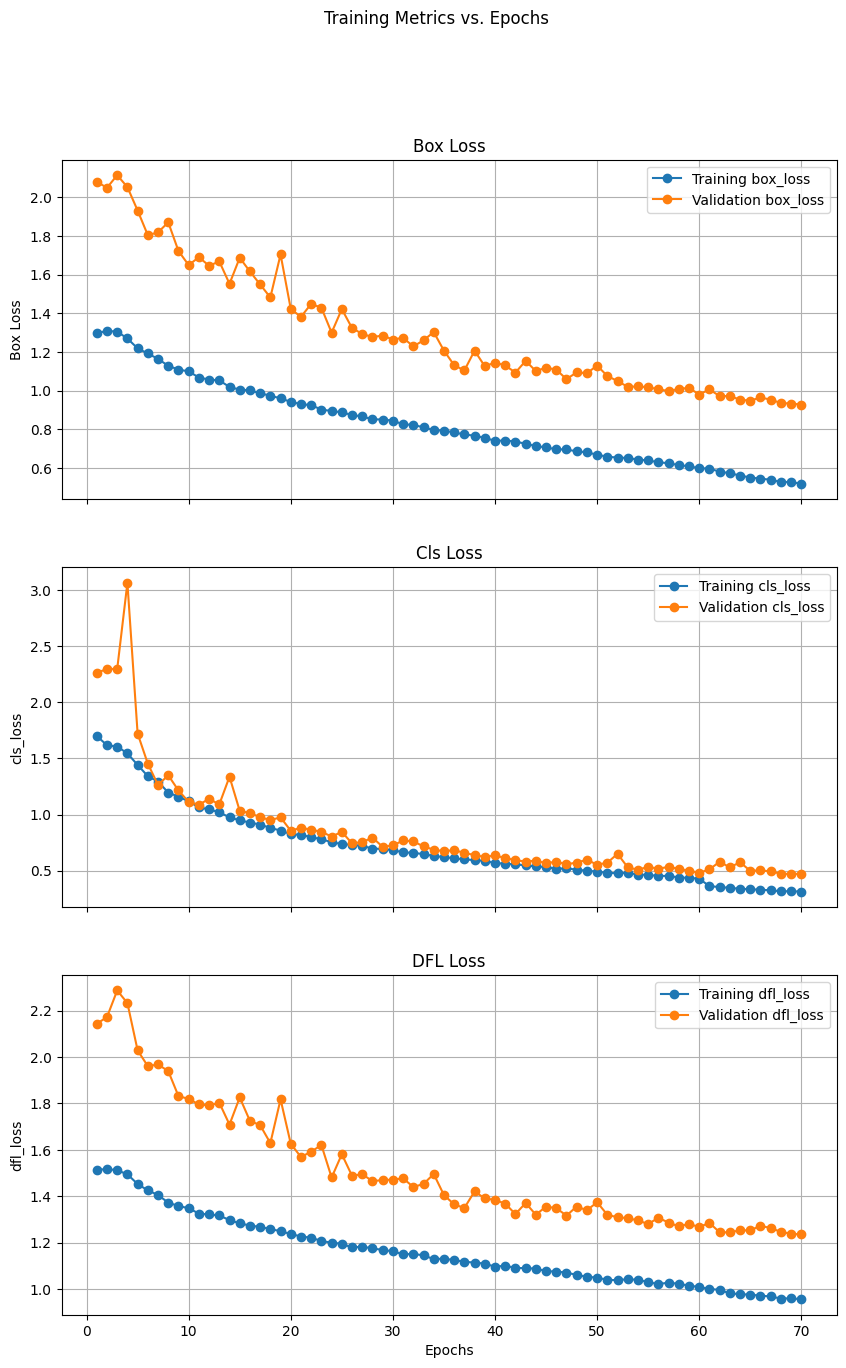

In [26]:
fig, (ax1, ax2, ax3) = plt.subplots(3, 1, figsize=(10, 15), sharex=True)

### Training and Validation box_loss
ax1.set_title('Box Loss')
ax1.plot(df['epoch'], df['train/box_loss'], label='Training box_loss', marker='o', linestyle='-')
ax1.plot(df['epoch'], df['val/box_loss'], label='Validation box_loss', marker='o', linestyle='-')
ax1.set_ylabel('Box Loss')
ax1.legend()
ax1.grid(True)

### Training and Validation cls_loss
ax2.set_title('Cls Loss')
ax2.plot(df['epoch'], df['train/cls_loss'], label='Training cls_loss', marker='o', linestyle='-')
ax2.plot(df['epoch'], df['val/cls_loss'], label='Validation cls_loss', marker='o', linestyle='-')
ax2.set_ylabel('cls_loss')
ax2.legend()
ax2.grid(True)

### Training and Validation dfl_loss
ax3.set_title('DFL Loss')
ax3.plot(df['epoch'], df['train/dfl_loss'], label='Training dfl_loss', marker='o', linestyle='-')
ax3.plot(df['epoch'], df['val/dfl_loss'], label='Validation dfl_loss', marker='o', linestyle='-')
ax3.set_xlabel('Epochs')
ax3.set_ylabel('dfl_loss')
ax3.legend()
ax3.grid(True)

plt.suptitle('Training Metrics vs. Epochs')
plt.show()

Validation results

In [27]:
validation_results_paths = [
    i for i in
    glob.glob(f'{CFG.OUTPUT_DIR}runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/*.png') +
    glob.glob(f'{CFG.OUTPUT_DIR}runs/detect/{CFG.BASE_MODEL}_{CFG.EXP_NAME}/*.jpg')
    if 'val_batch' in i
]

len(validation_results_paths)

6

In [28]:
if len(validation_results_paths) >= 1:
    print(validation_results_paths[-1])

./runs/detect/yolov9e_ppe_css_70_epochs/val_batch1_labels.jpg


./runs/detect/yolov9e_ppe_css_70_epochs/val_batch2_pred.jpg


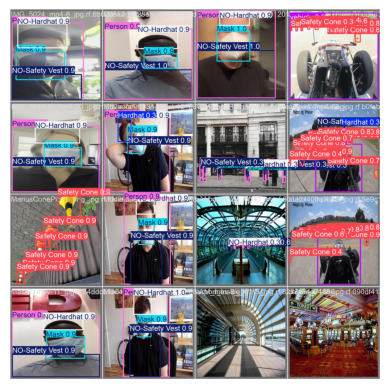

In [29]:
### check predictions or labels from a random validation batch
if len(validation_results_paths) >= 1:
    val_img_path = random.choice(validation_results_paths)
    print(val_img_path)
    display_image(val_img_path, print_info = False, hide_axis = True)